<a href="https://colab.research.google.com/github/oswrik/suscripcion_banco/blob/main/notebooks/05_interpretacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05 · Interpretación, sesgo y modelo final (Producto 2)
1. ¿Qué variables pesan más en la predicción?
2. ¿El modelo se equivoca más con algún grupo etario?
3. Guardamos el modelo final para la demo

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Datos: Bank Marketing (UCI, id 222)
URL = "https://raw.githubusercontent.com/oswrik/suscripcion_banco/refs/heads/main/data/bank-full.csv"

NUMERICAS = ["edad", "moroso", "saldo", "hipoteca", "prestamo",
             "dia", "campana", "dias_previos", "contactos_previos"]
CATEGORICAS = ["trabajo", "estado_civil", "educacion", "contacto", "mes", "resultado_previo"]

def cargar_datos():
    df = pd.read_csv(URL, sep=";")
    df.columns = [c.strip().lower() for c in df.columns]
    df = df.rename(columns={
        "age": "edad", "job": "trabajo", "marital": "estado_civil",
        "education": "educacion", "default": "moroso", "balance": "saldo",
        "housing": "hipoteca", "loan": "prestamo", "contact": "contacto",
        "day": "dia", "month": "mes", "campaign": "campana",
        "pdays": "dias_previos", "previous": "contactos_previos",
        "poutcome": "resultado_previo"})
    for col in ["moroso", "hipoteca", "prestamo"]:
        df[col] = (df[col].str.strip() == "yes").astype(int)
    df["suscribe"] = (df["y"].str.strip() == "yes").astype(int)
    return df[NUMERICAS + CATEGORICAS + ["suscribe"]]

df = cargar_datos()
X, y = df[NUMERICAS + CATEGORICAS], df["suscribe"]
print(df.shape, f"| suscriben: {y.mean():.1%}")

(45211, 16) | suscriben: 11.7%


In [2]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Misma división en todos los notebooks: el test se usa una sola vez, al final
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def preprocesador():
    num = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())])
    cat = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", num, NUMERICAS), ("cat", cat, CATEGORICAS)])

In [3]:
from lightgbm import LGBMClassifier
# Modelo final: LightGBM regularizado/optimizado (ganó en 25 de 25 folds en notebook 03)
final = Pipeline([("prep", preprocesador()),
                  ("modelo", LGBMClassifier(n_estimators=250, learning_rate=0.03, num_leaves=16,
                                            min_child_samples=50, subsample=0.8, subsample_freq=1,
                                            colsample_bytree=0.8, class_weight="balanced",
                                            random_state=42, verbose=-1))]).fit(X_tr, y_tr)

## 1 · Importancia por permutación (en el test)

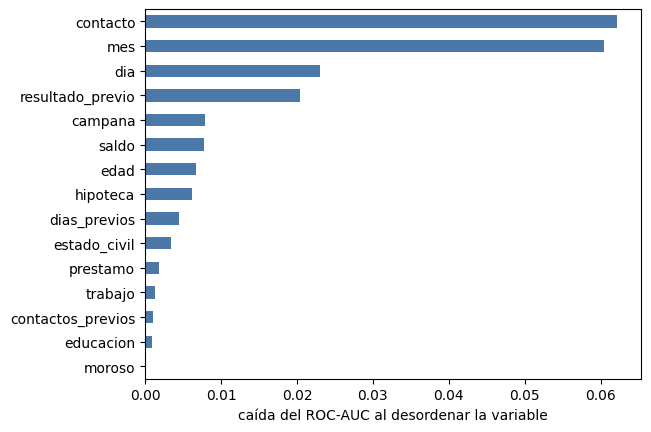

contacto            0.0622
mes                 0.0605
dia                 0.0230
resultado_previo    0.0205
campana             0.0079
saldo               0.0078
dtype: float64


In [4]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(final, X_te, y_te, scoring="roc_auc", n_repeats=10, random_state=42)
imp = pd.Series(perm.importances_mean, index=X_te.columns).sort_values()
imp.plot.barh(color="#4C78A8"); plt.xlabel("caída del ROC-AUC al desordenar la variable"); plt.show()
print(imp.sort_values(ascending=False).round(4).head(6))

## 2 · ¿Trata distinto según la edad del cliente?

In [5]:
from sklearn.metrics import recall_score, precision_score
pred = final.predict(X_te)
grupos_edad = pd.cut(X_te["edad"], [0, 30, 45, 60, 100], labels=["≤ 30 años", "31–45 años", "46–60 años", "> 60 años"])
for grupo in ["≤ 30 años", "31–45 años", "46–60 años", "> 60 años"]:
    m = grupos_edad == grupo
    print(f"{grupo:<12} n = {m.sum():>4} · recall = {recall_score(y_te[m], pred[m]):.2f} · "
          f"precisión = {precision_score(y_te[m], pred[m]):.2f}")

≤ 30 años    n = 1327 · recall = 0.75 · precisión = 0.31
31–45 años   n = 4748 · recall = 0.56 · precisión = 0.34
46–60 años   n = 2749 · recall = 0.58 · precisión = 0.37
> 60 años    n =  219 · recall = 1.00 · precisión = 0.43


**Lectura:** el modelo detecta una proporción muy alta de potenciales suscriptores entre jóvenes (`≤ 30`) y adultos mayores (`> 60`), mientras que su sensibilidad es menor en el grupo laboral intermedio (`31–60` años).

**Qué haríamos:** ajustar umbrales diferenciados por segmento o incorporar variables transaccionales que expliquen mejor el ahorro en adultos de mediana edad. El modelo solo debe emplearse para **priorizar llamadas comerciales**, nunca para excluir clientes de productos financieros.

## 3 · Guardar el modelo final para la demo

In [6]:
import joblib
joblib.dump(final, "modelo.joblib")
print("Guardado: descárguenlo del panel Archivos y súbanlo a la carpeta app/ del repositorio")

Guardado: descárguenlo del panel Archivos y súbanlo a la carpeta app/ del repositorio
